# M4 Validation: Delta Walk Traversal
End-to-end M4 validation with A1 (VAE encode/decode) and A3 latent injection.

In [1]:
from pathlib import Path
import torch
from IPython.display import display
from helpers.methods.access import decode_latents_to_image, encode_image_to_latents, vae_latents_to_denoiser_latents
from helpers.methods.navigation import delta_walks
from helpers.runtime.inference import generate_prompt_baseline, timed_generate_with_prompt
from helpers.runtime.pipeline import load_flux_pipeline, resolve_runtime_device
from helpers.runtime.utils import flush_namespace
from helpers.runtime.dtype_handler.parsing import resolve_dtype_for_device

WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.11.0+cu130)
    Python  3.10.11 (you have 3.13.11)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details
W0423 21:02:15.107000 4476 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Error occurred while checking dtype torch.float8_e4m3fn on device cuda: "ufunc_add_CUDA" not implemented for 'Float8_e4m3fn'
Candidate FP8 dtype float8_e4m3fn is not supported on device=cuda
Error occurred while checking dtype torch.float8_e5m2 on device cuda: "ufunc_add_CUDA" not implemented for 'Float8_e5m2'
Candidate FP8 dtype float8_e5m2 is not supported on device=cuda
Falling back from FP8 to torch.float16 on device=cuda; tested candidates=[float8_e4m3fn, float8_e5m2]
Enabled layerwise casting on transformer (storage=torch.float16, compute=torch.bfloat16)
Layerwise casting not enabled; skipping fallback attempt


The module 'Flux2Transformer2DModel' is group offloaded and moving it to cuda via `.to()` is not supported.


Enabled group offloading for text_encoder (offload_type=block_level)
Enabled group offloading for vae (offload_type=leaf_level)
Loaded pipeline with transformer group offload enabled (use_stream=True, low_cpu_mem_usage=False, enable_text_encoder_group_offload=True, enable_vae_group_offload=True)
Enabled VAE slicing via vae.enable_slicing()
Enabled VAE tiling via vae.enable_tiling()
Enabled channels-last memory format on vae
Skipping xFormers attention: No operator found for `memory_efficient_attention_forward` with inputs:
     query       : shape=(1, 2, 1, 40) (torch.float32)
     key         : shape=(1, 2, 1, 40) (torch.float32)
     value       : shape=(1, 2, 1, 40) (torch.float32)
     attn_bias   : <class 'NoneType'>
     p           : 0.0
`fa3F@0.0.0` is not supported because:
    xFormers wasn't build with CUDA support
    requires device with capability >= (8, 0) but your GPU has capability (7, 5) (too old)
    dtype=torch.float32 (supported: {torch.bfloat16, torch.float16})
  

  0%|          | 0/3 [00:00<?, ?it/s]

baseline in 114.89 s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\navigation\outputs\m4_delta_walk_notebook\m4_baseline.png


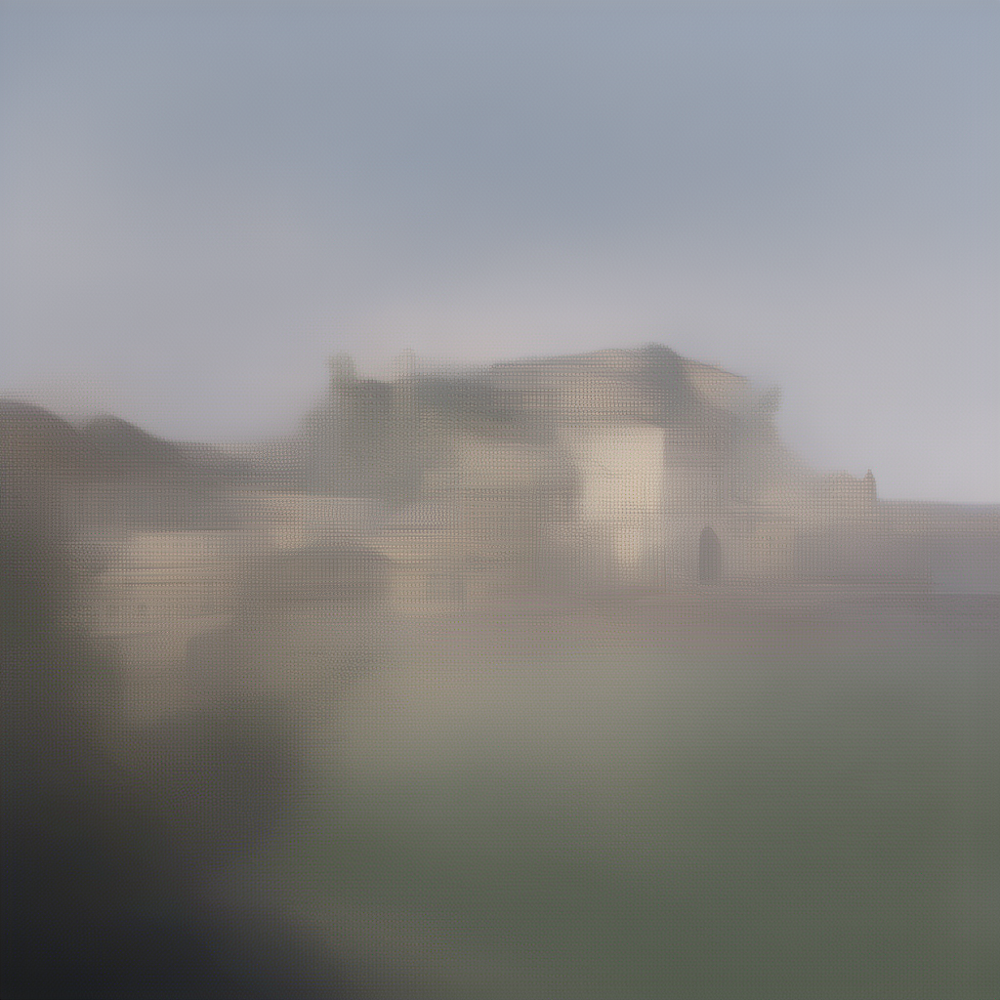

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

anchor_a in 259.74 s
anchor_b in 254.31 s


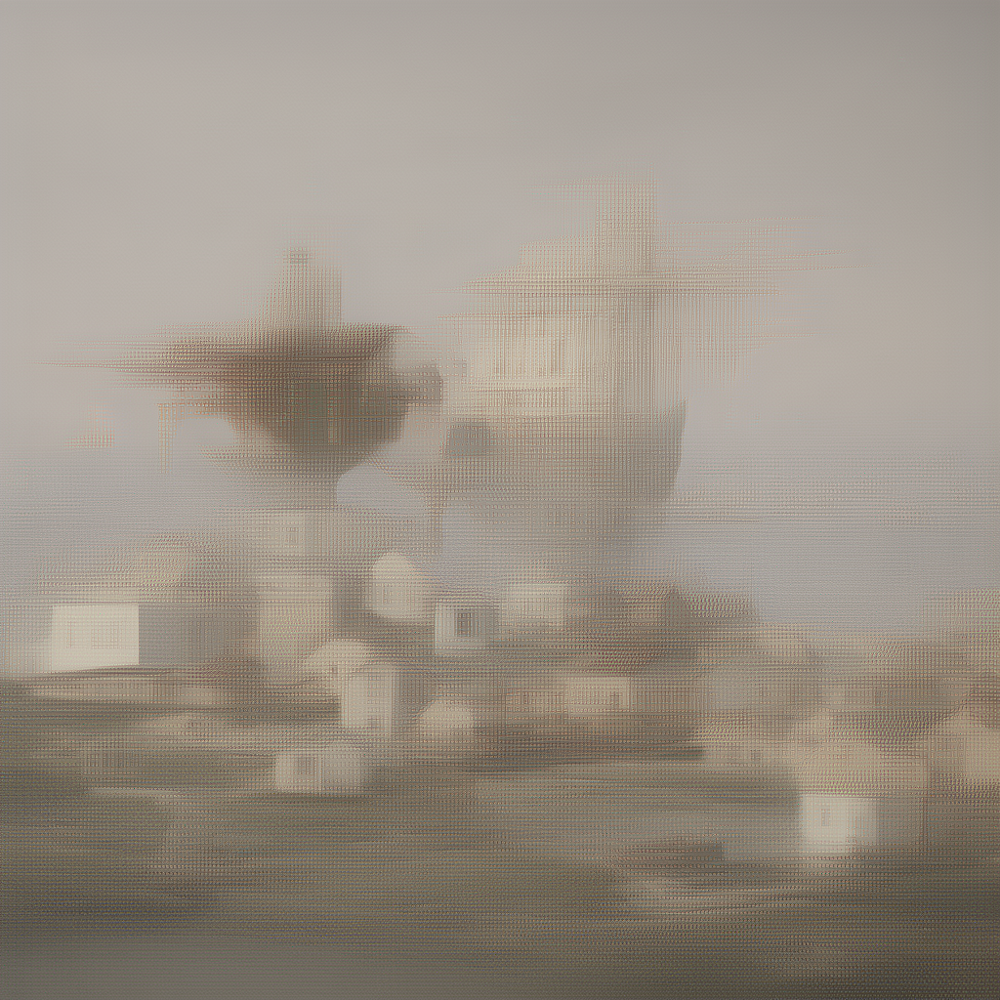

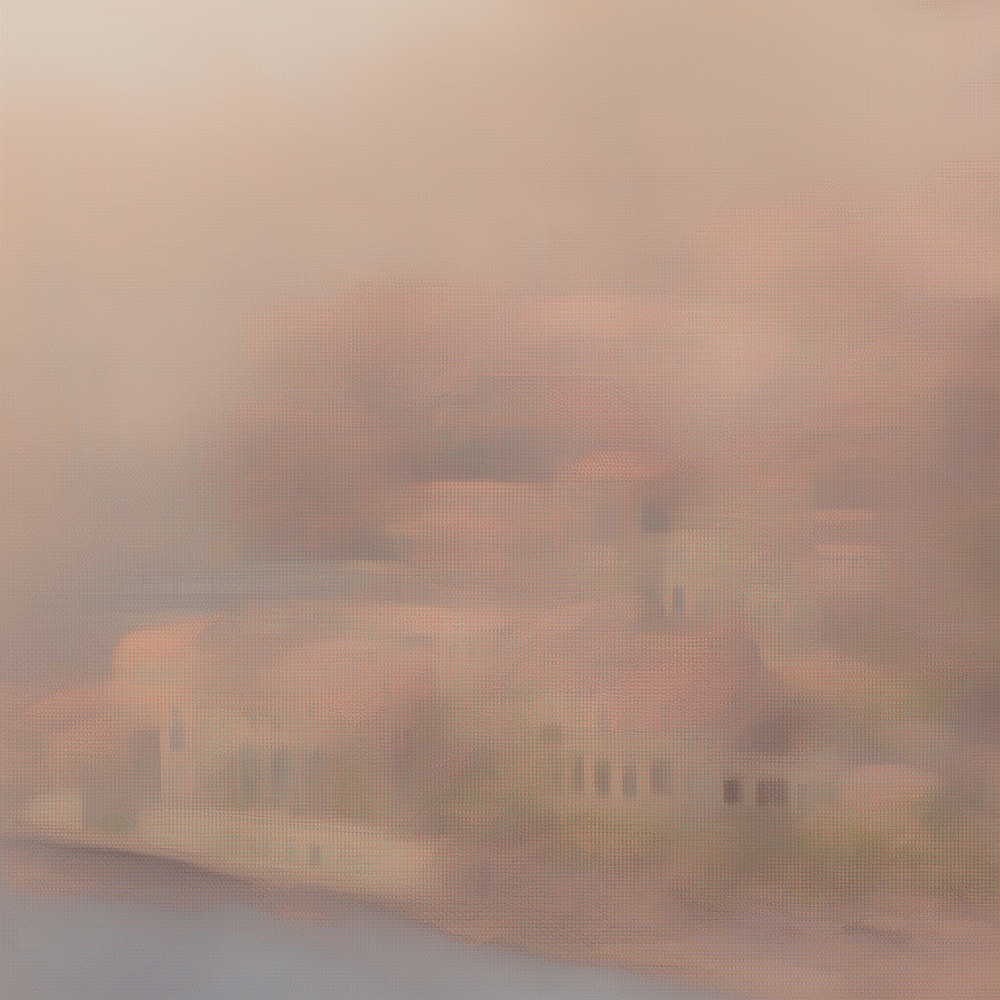

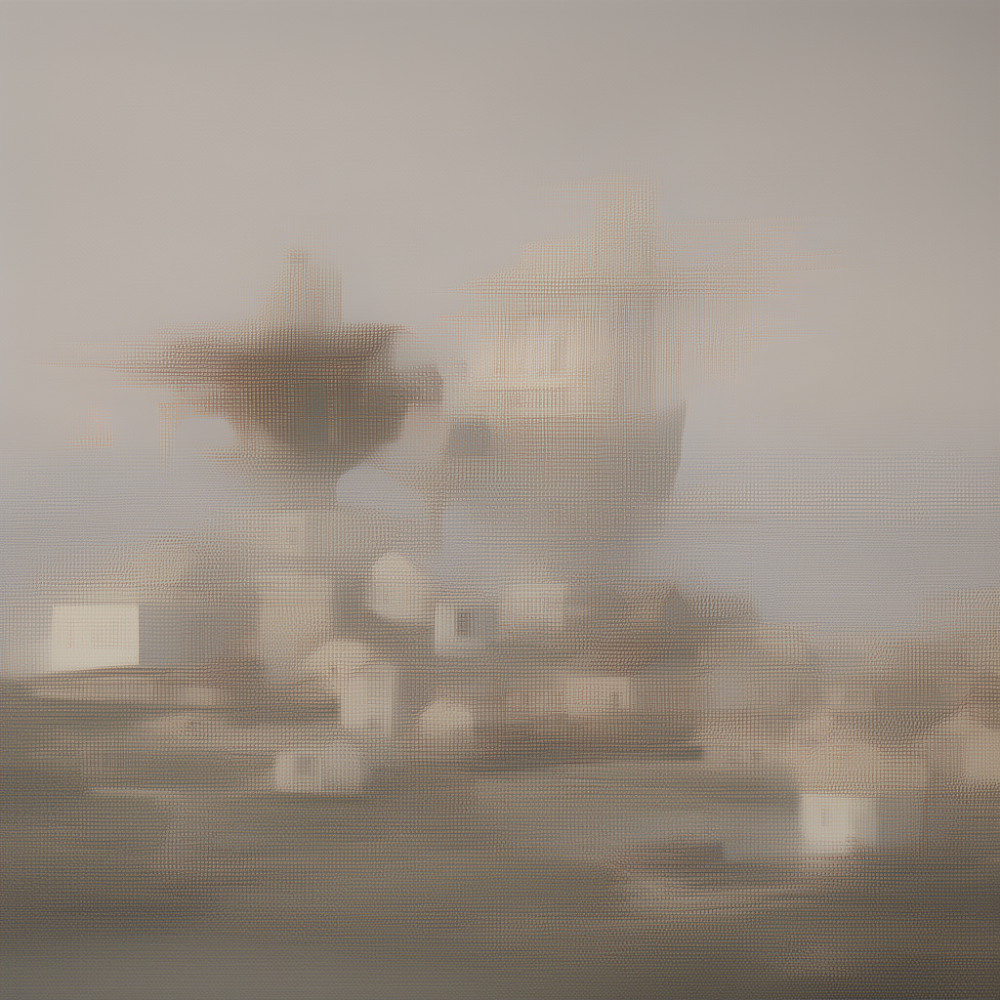

  0%|          | 0/3 [00:00<?, ?it/s]

scale=+0.00 in 258.11s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\navigation\outputs\m4_delta_walk_notebook\m4_delta_scale_+0.00.png


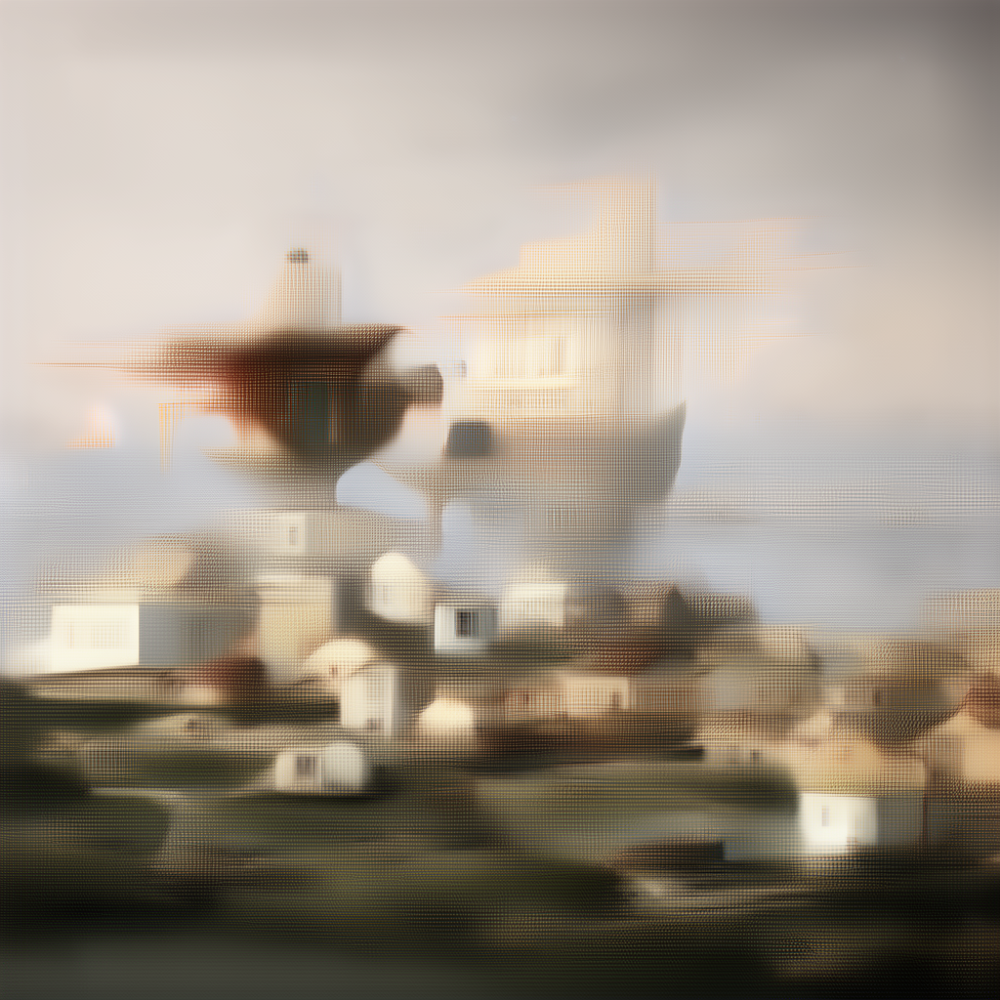

  0%|          | 0/3 [00:00<?, ?it/s]

scale=+0.75 in 266.99s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\navigation\outputs\m4_delta_walk_notebook\m4_delta_scale_+0.75.png


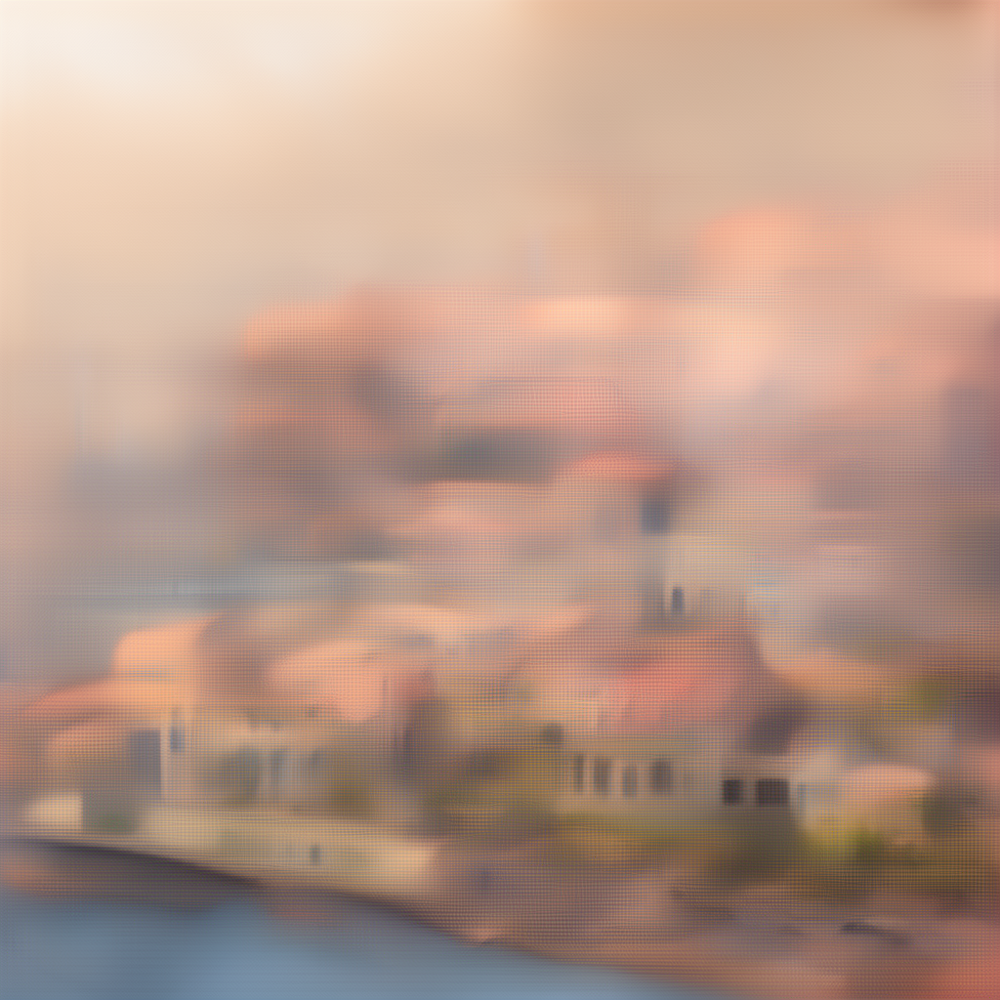

  0%|          | 0/3 [00:00<?, ?it/s]

scale=+1.50 in 315.81s -> C:\Users\David\Desktop\thesis\NeLs\project\python\examples\navigation\outputs\m4_delta_walk_notebook\m4_delta_scale_+1.50.png


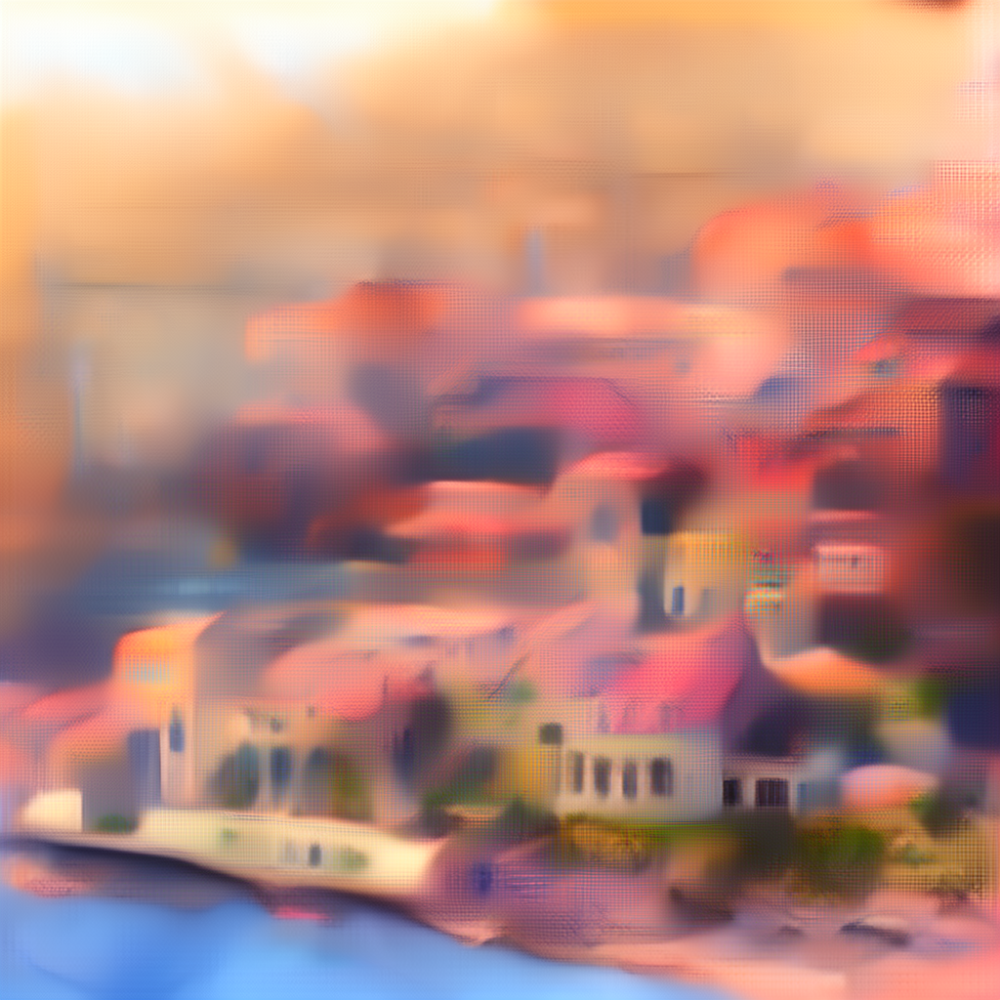

Before flush: allocated=0.02 GB, reserved=8.29 GB, peak_allocated=7.79 GB
After flush: allocated=0.01 GB, reserved=0.03 GB, peak_allocated=0.01 GB


In [ ]:
output_dir = Path('../python/examples/navigation/outputs/m4_delta_walk_notebook').resolve()
output_dir.mkdir(parents=True, exist_ok=True)

device = resolve_runtime_device()
dtype = resolve_dtype_for_device(device=device)

prompt = 'a calm coastal village with detailed architecture'
num_inference_steps = 3
guidance_scale = 0.0
try:
    pipe = load_flux_pipeline(
        torch_dtype=dtype,
        device=device,
        offload_mode="none",
        enable_vae_slicing=False,
        enable_vae_tiling=False,
        enable_layerwise_casting=False,
        enable_channels_last=True,
        enable_xformers_attention=True,
        enable_torch_compile=False,
        disable_progress_bar=False
    )

    baseline_image, baseline_elapsed, _ = generate_prompt_baseline(
        pipe=pipe,
        prompt=prompt,
        seed=321,
        device=device,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
    )
    baseline_path = output_dir / 'm4_baseline.png'
    baseline_image.save(baseline_path)

    print(f'baseline in {baseline_elapsed:.2f} s -> {baseline_path}')
    display(baseline_image)

    anchor_a_out, anchor_a_elapsed = timed_generate_with_prompt(
        pipe=pipe,
        prompt=prompt,
        seed=12,
        device=device,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
    )
    anchor_b_out, anchor_b_elapsed = timed_generate_with_prompt(
        pipe=pipe,
        prompt=prompt,
        seed=96,
        device=device,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
    )
    anchor_a = anchor_a_out.images[0]
    anchor_b = anchor_b_out.images[0]
    print(f'anchor_a in {anchor_a_elapsed:.2f} s')
    print(f'anchor_b in {anchor_b_elapsed:.2f} s')
    anchor_a.save(output_dir / "m4_anchor_a.png")
    anchor_b.save(output_dir / "m4_anchor_b.png")
    display(anchor_a)
    display(anchor_b)

    latent_a = encode_image_to_latents(pipe=pipe, image=anchor_a, size=None, sample_posterior=False, device='cpu', dtype=dtype)
    latent_b = encode_image_to_latents(pipe=pipe, image=anchor_b, size=None, sample_posterior=False, device='cpu', dtype=dtype)
    latent_a_denoiser = vae_latents_to_denoiser_latents(pipe, latent_a)
    latent_b_denoiser = vae_latents_to_denoiser_latents(pipe, latent_b)

    preview = decode_latents_to_image(pipe, latent_a)
    display(preview)

    scales = [0.0, 0.75, 1.5]
    walked = delta_walks(latent_a_denoiser, latent_b_denoiser, scales=scales)

    for scale, walked_latent in zip(scales, walked):
        out, elapsed = timed_generate_with_prompt(
            pipe=pipe,
            prompt=prompt,
            seed=321,
            device=device,
            latents=walked_latent,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
        )
        image = out.images[0]

        path = output_dir / f'm4_delta_scale_{scale:+.2f}.png'
        image.save(path)

        print(f'scale={scale:+.2f} in {elapsed:.2f}s -> {path}')
        display(image)
finally:
    flush_namespace(
        globals(),
        "pipe",
        "out",
        "image",
        "anchor_a_out",
        "anchor_b_out",
        "anchor_a",
        "anchor_b",
        "latent_a",
        "latent_b",
        "latent_a_denoiser",
        "latent_b_denoiser",
        "baseline_image",
        "preview",
        verbose=True,
        hard_exit=True
    )